Para ajuda-los a fazer a atividade 3, eu preparei este notebook para ser usado no Google Colab, onde eu faço o treinamento e testo o YOLO com peças de jogo de xadrez.

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 5.0 MB/s eta 0:00:00


In [ ]:
import ultralytics
ultralytics.checks()
# confirma versão e GPU disponível

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [ ]:
from google.colab import files
uploaded = files.upload()   # escolha xadrez3.zip na janela que abrir

Saving xadrez3.zip to xadrez3.zip


In [ ]:
import os, glob, zipfile

# Descompactar o zip enviado
with zipfile.ZipFile("xadrez3.zip") as z:
    z.extractall("/content/dataset")

# Localizar o data.yaml (pode estar em uma subpasta)
yamls = glob.glob("/content/dataset/**/data.yaml", recursive=True)
print(yamls)
root = os.path.dirname(yamls[0])

print(open(f"{root}/data.yaml").read())

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

['/content/dataset/data.yaml']
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']

roboflow:
  workspace: ffambrini
  project: chess-ovkj7-psowd
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/ffambrini/chess-ovkj7-psowd/dataset/1
train -> imagens: 410 | labels: 410
valid -> imagens: 157 | labels: 157
test -> imagens: 64 | labels: 64


In [ ]:
import os, glob

root = "/content/dataset"  # ajuste para a sua pasta
print(open(f"{root}/data.yaml").read())  # conteúdo do data.yaml

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']

roboflow:
  workspace: ffambrini
  project: chess-ovkj7-psowd
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/ffambrini/chess-ovkj7-psowd/dataset/1
train -> imagens: 410 | labels: 410
valid -> imagens: 157 | labels: 157
test -> imagens: 64 | labels: 64


In [ ]:
import os, glob

yamls = glob.glob("/content/dataset/**/data.yaml", recursive=True)
print(yamls)

root = os.path.dirname(yamls[0])
print("root =", root)
print(open(f"{root}/data.yaml").read())

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))


['/content/dataset/data.yaml']
root = /content/dataset
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']

roboflow:
  workspace: ffambrini
  project: chess-ovkj7-psowd
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/ffambrini/chess-ovkj7-psowd/dataset/1
train -> imagens: 410 | labels: 410
valid -> imagens: 157 | labels: 157
test -> imagens: 64 | labels: 64


In [ ]:
!ls -la /content
!unzip -l /content/xadrez3.zip | head -30
!find /content/dataset | head -40


total 17288
drwxr-xr-x 1 root root     4096 Oct 16 22:24 .
drwxr-xr-x 1 root root     4096 Oct 16 22:07 ..
drwxr-xr-x 4 root root     4096 Sep 30 13:28 .config
drwxr-xr-x 5 root root     4096 Oct 16 22:25 dataset
-rw-r--r-- 1 root root 17678388 Oct 16 22:24 xadrez3.zip
Archive:  /content/xadrez3.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
    30400  2026-10-03 16:23   test/images/00000134_resized_jpg.rf.ad32be017a6472018659769325805704.jpg
    39170  2026-10-03 16:23   test/images/00000028_resized_jpg.rf.adf8282bb124d536c3f2463deffd23cd.jpg
    38906  2026-10-03 16:23   test/images/00000235_resized_jpg.rf.791dd7e67b2f3d4d48cad7484d4d4ab5.jpg
    23319  2026-10-03 16:23   test/images/00000046_resized_jpg.rf.231b7a5b28483150969f82e3808beef4.jpg
    37157  2026-10-03 16:23   test/images/00000153_resized_jpg.rf.303e5f1116bb46d44d4de46fbcfde0b0.jpg
    36614  2026-10-03 16:23   valid/images/00000011_resized_jpg.rf.649f04c9e61f85080cc48f90b98b95f1.jpg
    33023 

In [ ]:
!ls -la /content
!find /content -name "data.yaml" 2>/dev/null

total 17288
drwxr-xr-x 1 root root     4096 Oct 16 22:24 .
drwxr-xr-x 1 root root     4096 Oct 16 22:07 ..
drwxr-xr-x 4 root root     4096 Sep 30 13:28 .config
drwxr-xr-x 5 root root     4096 Oct 16 22:25 dataset
-rw-r--r-- 1 root root 17678388 Oct 16 22:24 xadrez3.zip
/content/dataset/data.yaml


In [ ]:
!mkdir -p /content/dataset
!unzip -o /content/xadrez3.zip -d /content/dataset | tail -10
!find /content/dataset -maxdepth 3 | head -40


  inflating: /content/dataset/train/labels/00000026_resized_jpg.rf.dfc4d8bfe3311554ca35cdee3763fe96.txt  
  inflating: /content/dataset/train/labels/00000247_resized_jpg.rf.1d1ab3b2d2128e03b8d5dbdafebeeba5.txt  
  inflating: /content/dataset/train/labels/00000157_resized_jpg.rf.d98be2b74804da1c5aeef094c517aa47.txt  
  inflating: /content/dataset/train/labels/00000082_resized_jpg.rf.12392bc944f5897e4406e74960937cce.txt  
  inflating: /content/dataset/train/labels/00000089_resized_jpg.rf.cb4f5829572c6e99060b2539702d4c80.txt  
  inflating: /content/dataset/train/labels/00000026_resized_jpg.rf.6c88660a92b59c54d0fcd9cb3741e769.txt  
  inflating: /content/dataset/train/labels/00000159_resized_jpg.rf.e152aaf2c7c15c673e560e01e6d58da5.txt  
  inflating: /content/dataset/data.yaml  
  inflating: /content/dataset/README.roboflow.txt  
  inflating: /content/dataset/README.dataset.txt  
/content/dataset
/content/dataset/train
/content/dataset/train/images
/content/dataset/train/images/00000083_resi

In [ ]:
import os, glob

yamls = glob.glob("/content/dataset/**/data.yaml", recursive=True)
print(yamls)

root = os.path.dirname(yamls[0])
print("root =", root)
print(open(f"{root}/data.yaml").read())

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

['/content/dataset/data.yaml']
root = /content/dataset
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']

roboflow:
  workspace: ffambrini
  project: chess-ovkj7-psowd
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/ffambrini/chess-ovkj7-psowd/dataset/1
train -> imagens: 410 | labels: 410
valid -> imagens: 157 | labels: 157
test -> imagens: 64 | labels: 64


In [ ]:
# 1) Corrige os caminhos do data.yaml (evita erro de pasta nao encontrada)
root = "/content/dataset"
yaml_text = f"""path: {root}
train: train/images
val: valid/images
test: test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']
"""
open(f"{root}/data.yaml", "w").write(yaml_text)
print(open(f"{root}/data.yaml").read())

path: /content/dataset
train: train/images
val: valid/images
test: test/images

nc: 5
names: ['bishop', 'knight', 'pawn', 'queen', 'rook']



In [ ]:
# 2) Instala e treina (ative a GPU: Ambiente de execucao > Alterar tipo > T4)
!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO("yolo11n.pt")  # pesos pre-treinados (transfer learning)
results = model.train(
    data="/content/dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/runs",
    name="xadrez_ft",
)


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=xadrez_ft, nbs=64, nms=None, opset=None, optimize=False, optimi

    epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
45     46               0.87132            0.90542           0.94414   
46     47               0.87910            0.87464           0.92963   
47     48               0.86455            0.89919           0.94471   
48     49               0.92382            0.86124           0.94274   
49     50               0.92614            0.87086           0.94544   

    metrics/mAP50-95(B)  
45              0.66863  
46              0.65199  
47              0.65814  
48              0.67285  
49              0.67913  


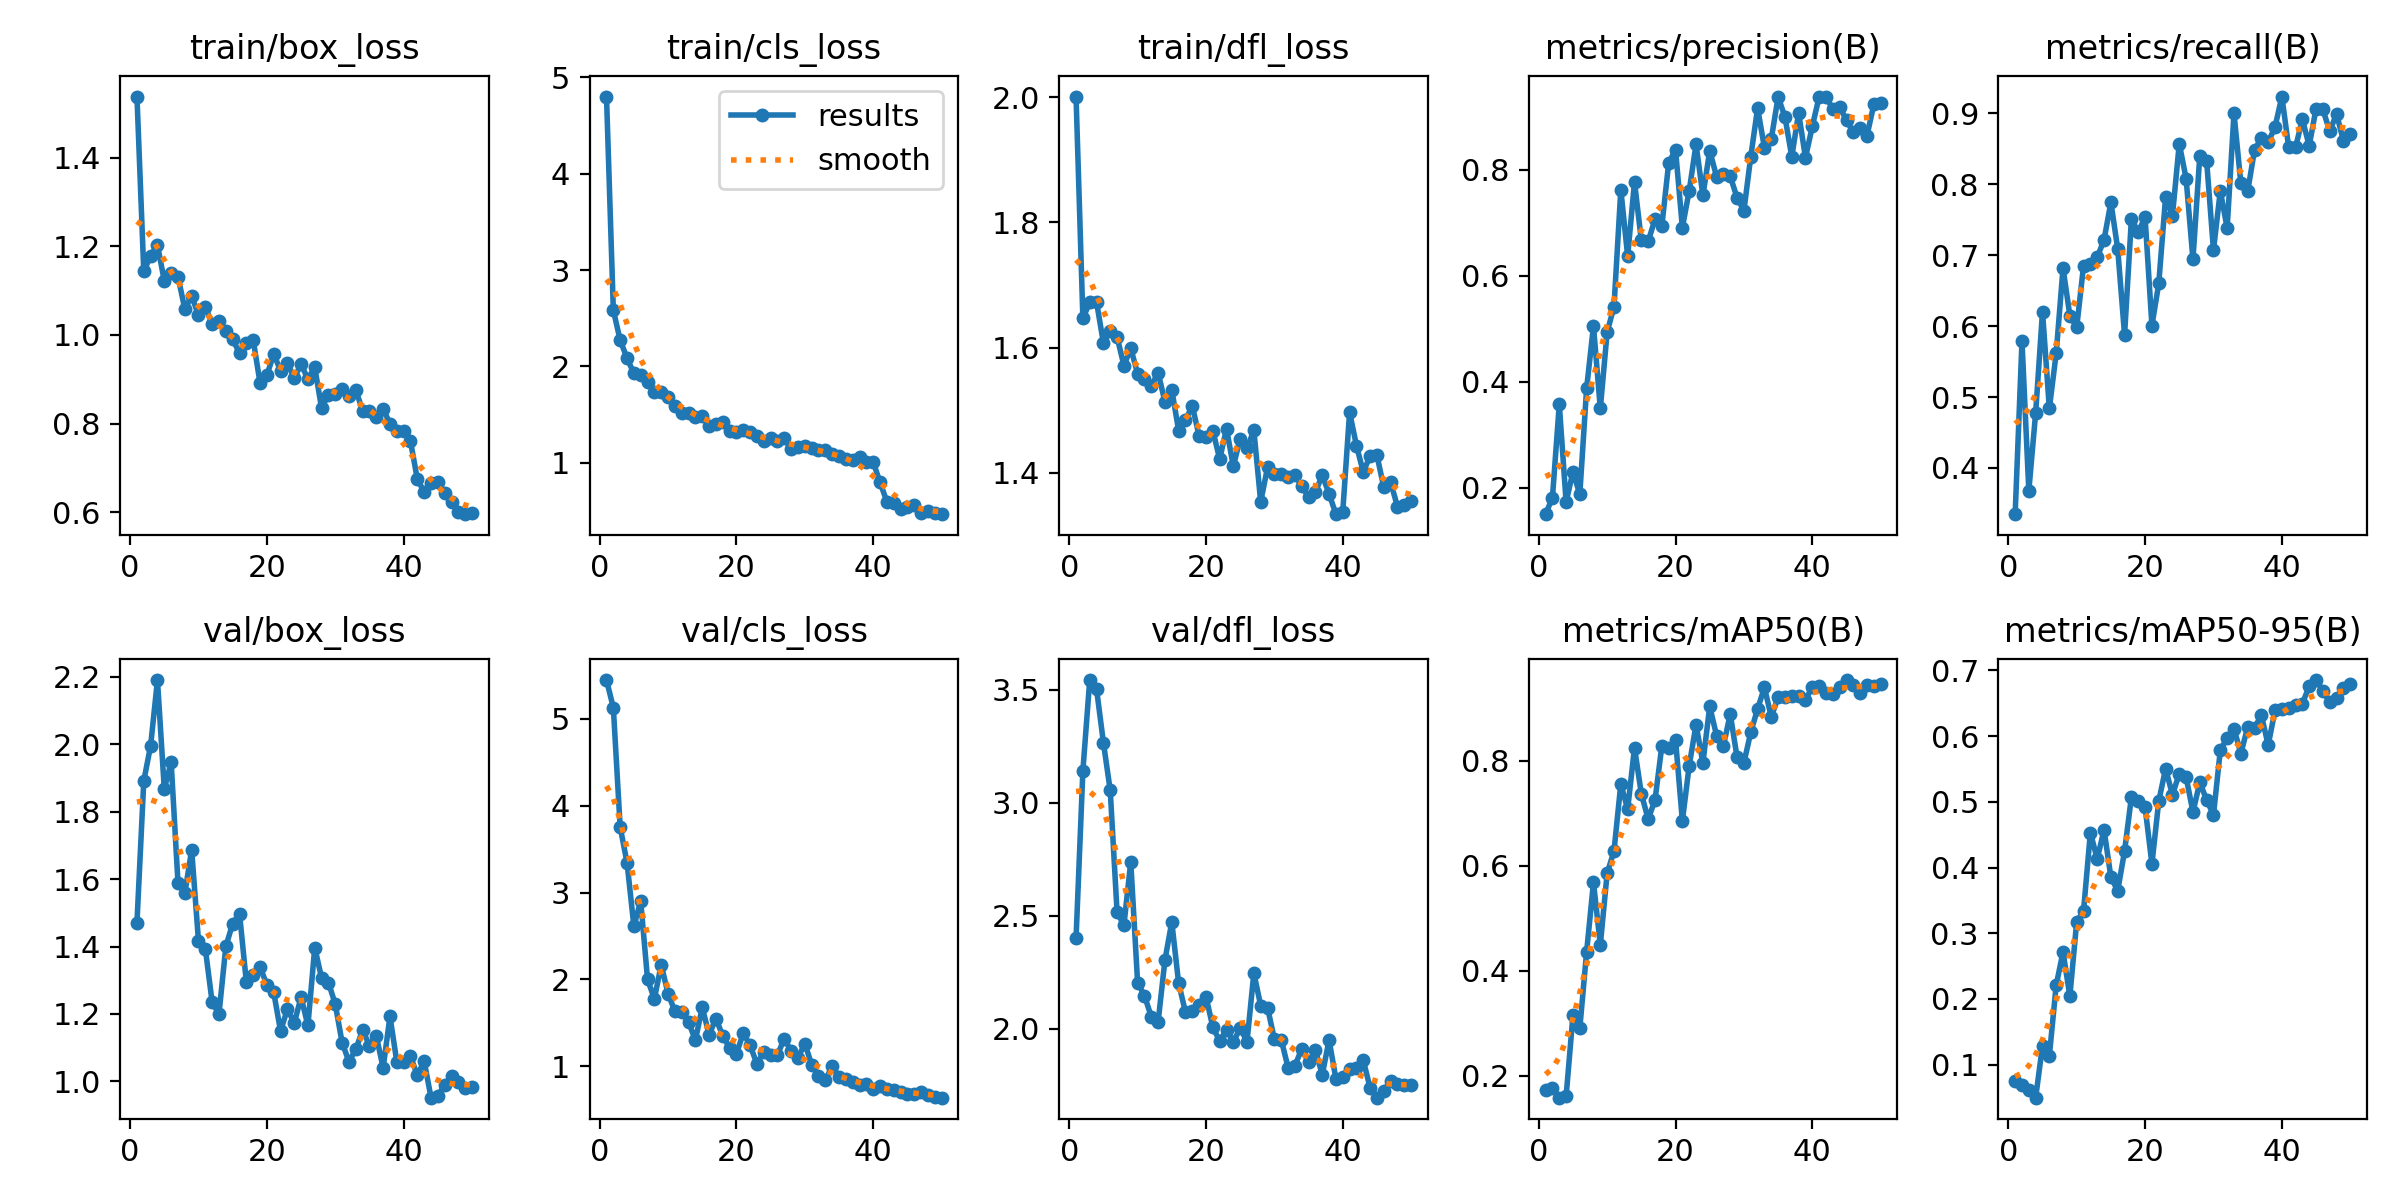

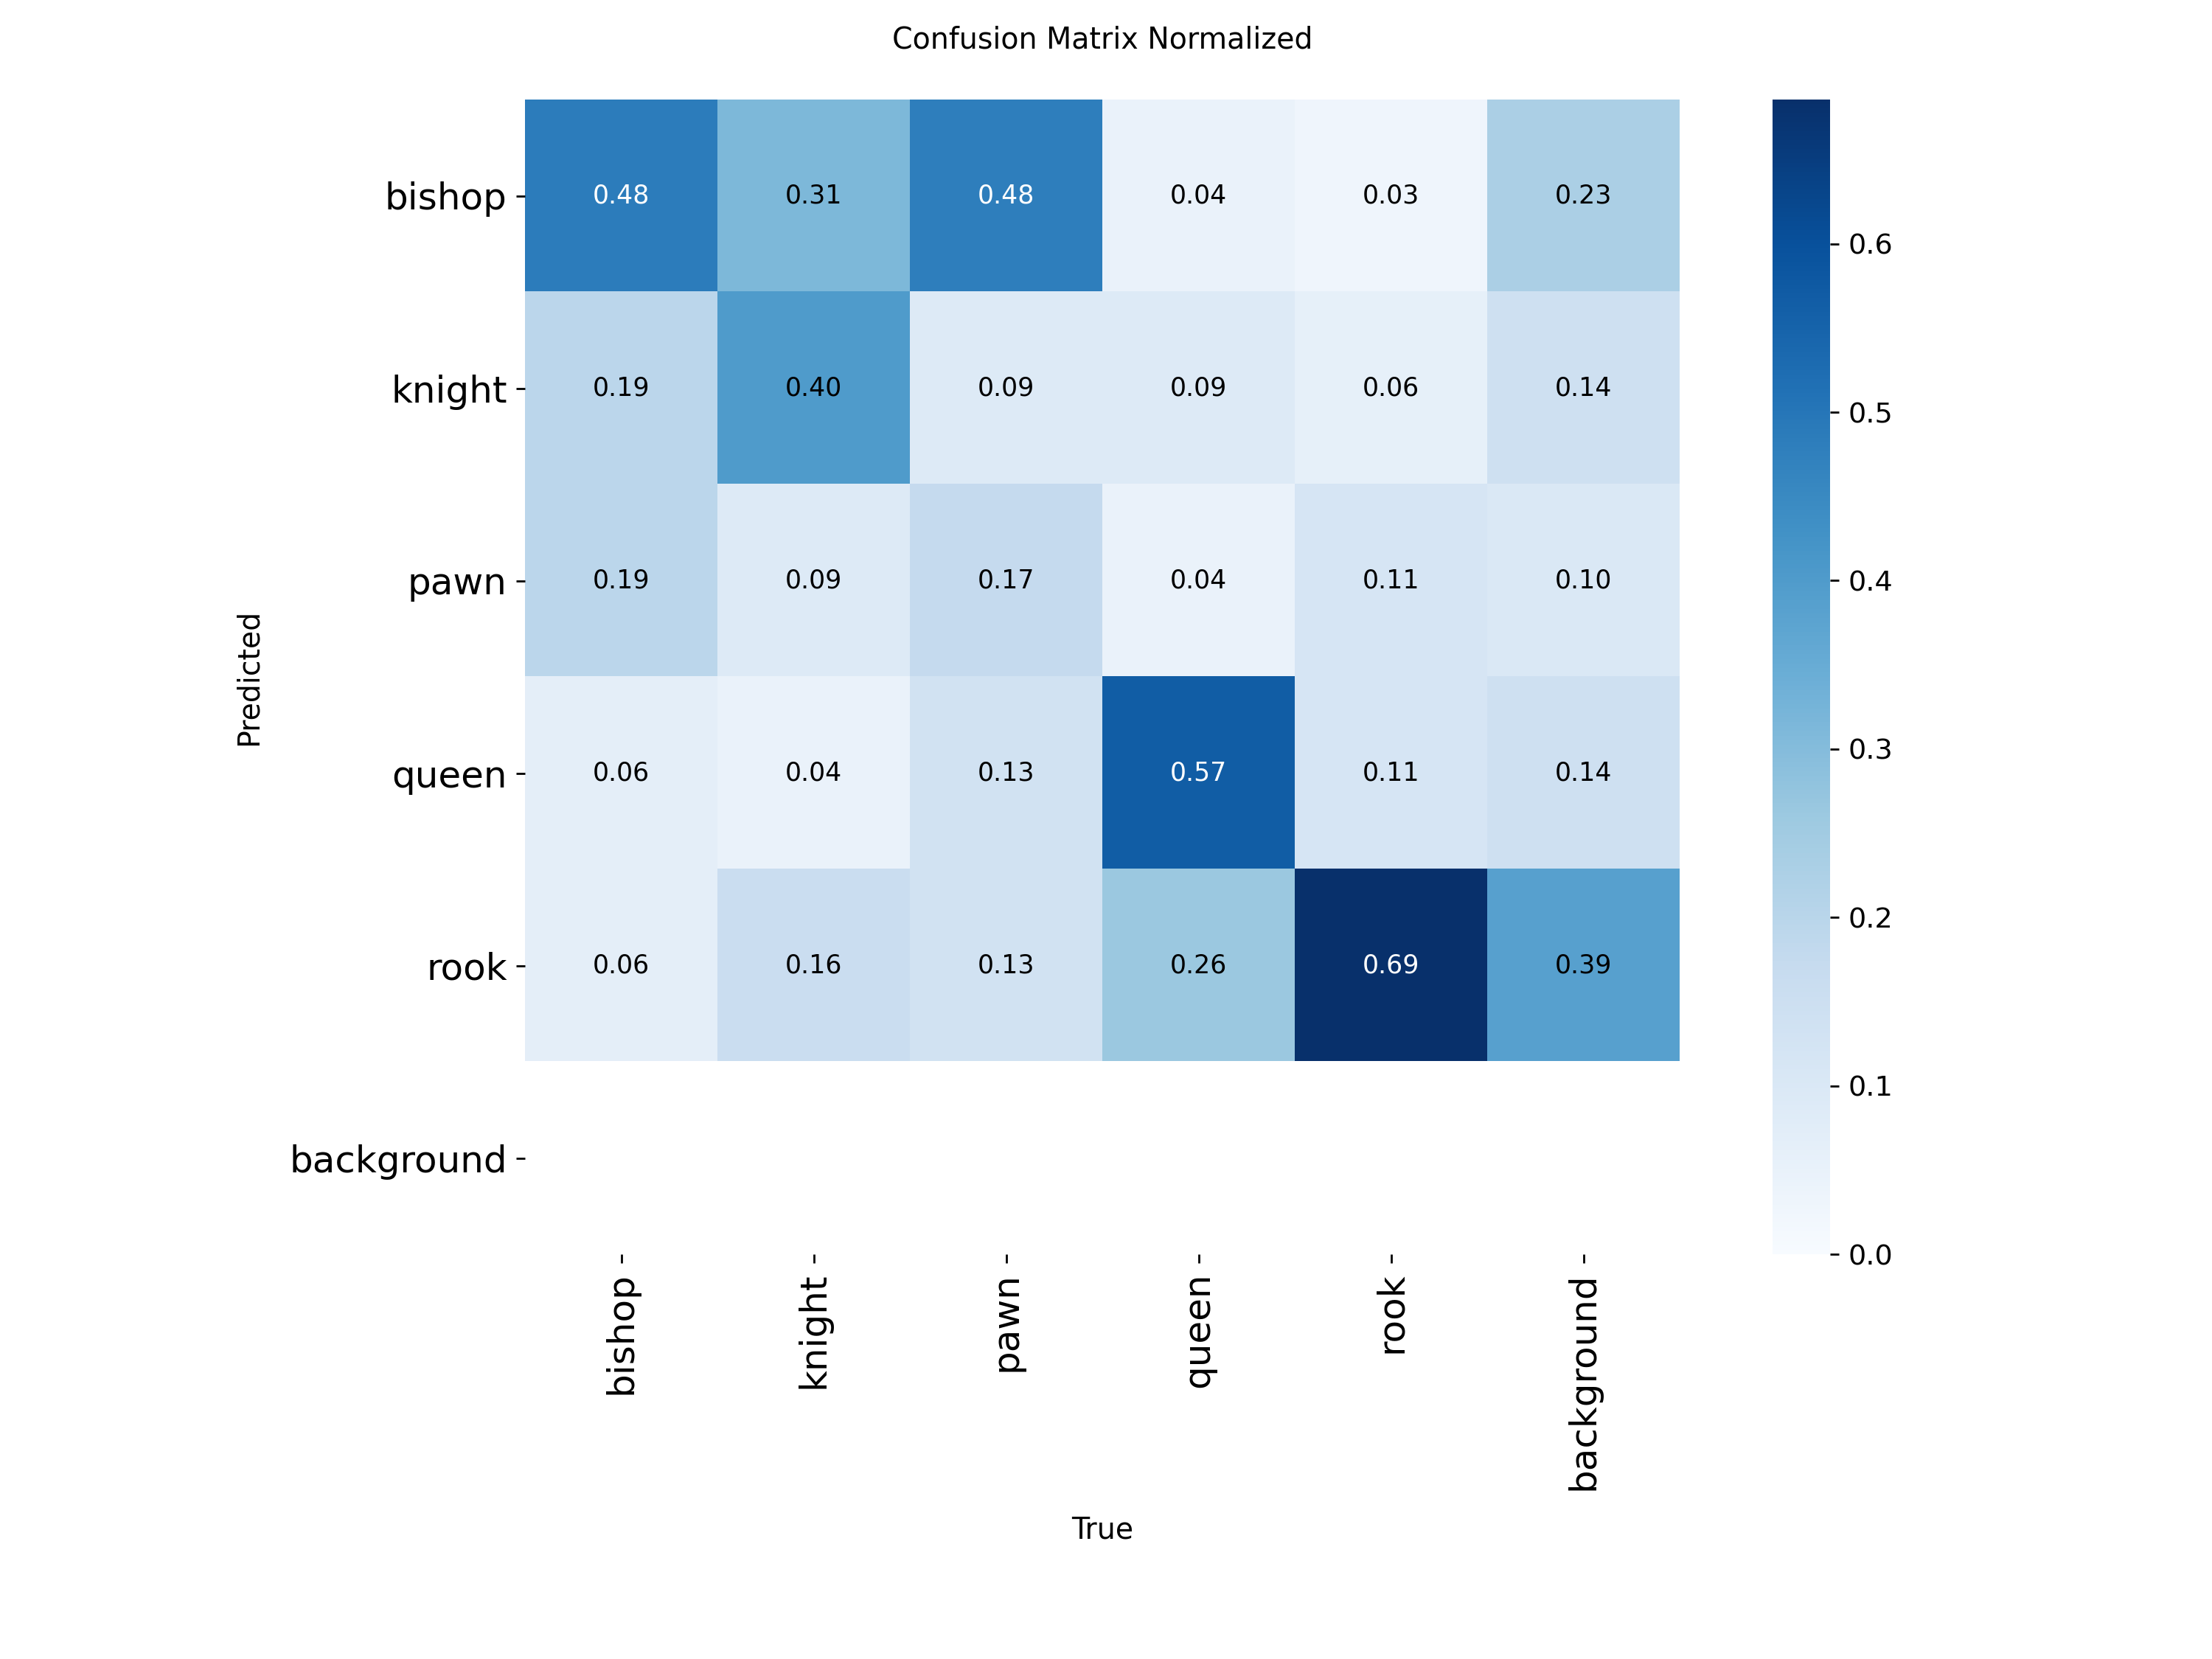

In [ ]:
from IPython.display import Image, display
import pandas as pd

# métricas finais por época
df = pd.read_csv("/content/runs/xadrez_ft/results.csv")
df.columns = df.columns.str.strip()
print(df[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(5))

# gráficos e matriz de confusão
display(Image("/content/runs/xadrez_ft/results.png", width=900))
display(Image("/content/runs/xadrez_ft/confusion_matrix_normalized.png", width=600))


Saving IMAGEM_TESTE_PEAO.jpg to IMAGEM_TESTE_PEAO.jpg

image 1/1 /content/IMAGEM_TESTE_PEAO.jpg: 640x384 1 pawn, 8.2ms
Speed: 1.9ms preprocess, 8.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /content/runs/teste


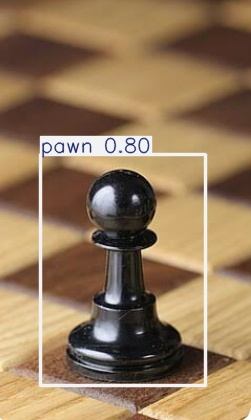

pawn 0.801


In [ ]:
from google.colab import files
from ultralytics import YOLO
from IPython.display import Image, display
import glob

# 1) envie a imagem
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2) carregue o modelo treinado e faça a predição
model = YOLO("/content/runs/xadrez_ft/weights/best.pt")
results = model.predict(img_path, conf=0.25, save=True, project="/content/runs", name="teste", exist_ok=True)

# 3) mostre o resultado
for p in glob.glob("/content/runs/teste/*"):
    display(Image(p, width=400))

# 4) liste as detecções
for box in results[0].boxes:
    print(model.names[int(box.cls)], round(float(box.conf), 3))

In [ ]:
from google.colab import files
files.download("/content/runs/xadrez_ft/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>